# Build a Basic ChatBot With LangGraph ( Graph API )

In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    #
    messages:Annotated[list,add_messages]



In [3]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
llm = init_chat_model("groq:qwen/qwen3.8-27b")

# llm = ChatGroq( model="qwen/qwen3.6-27b")


In [6]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [7]:
graph_builder = StateGraph(State)
graph_builder.add_node("llmchatbot",chatbot)

graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)


graph = graph_builder.compile()


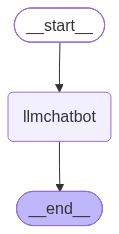

In [8]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
response = graph.invoke({"messages":"Hi How Are You"})


In [ ]:
response["messages"][-1].content

[HumanMessage(content='Hi How Are You', additional_kwargs={}, response_metadata={}, id='9102b77f-2c97-4676-a176-0b372d7c97be'),
 AIMessage(content="I'm doing well, thank you for asking! How are you doing today?\n\nIs there anything specific on your mind, or is there something I can help you with?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 36, 'prompt_tokens': 16, 'total_tokens': 52, 'completion_time': 0.068585612, 'completion_tokens_details': None, 'prompt_time': 0.000875177, 'prompt_tokens_details': None, 'queue_time': 0.043748212, 'total_time': 0.069460789}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12fa1-a2e9-7a03-b961-5b48f254ff29-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 36, 'total_tokens': 52})]

In [16]:
for event in graph.stream({"messages":"Hi, How are you ?"}):
    for value in event.values():
        print(value["messages"][-1].content)

I'm doing well, thank you! How are you doing today? Is there something specific I can help you with?


## ChatBot with Tool

In [9]:
from langchain_tavily import TavilySearch

tool =  TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [12]:
## Custom Function

def multiply(a:int,b:int)->int:
    """ multiply a and b 
     
     Args:
         a(int): First int
         b(int): Second int

    Return:
        int: output int
    """
    return a*b

In [13]:
tools = [tool,multiply]

In [14]:
llm_with_tools=llm.bind_tools(tools)

In [15]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.4.8', 'langchain': '1.3.11'}}, output_version=None, client=<groq.resources.chat.completions.Completions object at 0x10de42cf0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x10de43560>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_

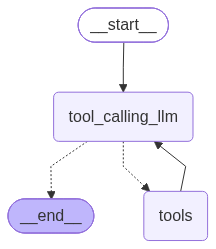

In [16]:
## StateGraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node Defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edge
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message(Result) from assistant is a tool call -> tools_condition route to the tools
    #If the latest message(Result) from assistant is not a tool call -> tools_condition route to the END
    tools_condition
    )
builder.add_edge("tools","tool_calling_llm")

## comnpile the graph
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))



In [ ]:
response = graph.invoke({"messages":"What is the recent AI news"})
# response = graph.invoke({"messages":"What is 2 mulitply by 4"})

In [60]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news
================================== Ai Message ==================================

Here are the most recent major developments in the AI world, spanning the last few months:

### **1. The "Agentic AI" Era & Enterprise Adoption**
*   **Agentic Workflows:** The industry has shifted from simple chatbots to "Agentic AI"—autonomous agents that can plan, use tools, and execute multi-step tasks. This is driving massive investment in enterprise infrastructure.
*   **Microsoft & OpenAI:** Both have heavily focused on bringing agentic capabilities to enterprise customers, with Microsoft integrating these into Windows 11 and Office 365, and OpenAI pushing its "Operator" and agent capabilities.

### **2. Major Model Releases**
*   **Google Gemini 2.5 (and Flash 2.5):** Google released its latest frontier models, emphasizing significantly improved reasoning, coding, and video generation capab

In [18]:
response = graph.invoke({"messages":"What is the recent AI news and What is 2 mulitplied by 10 "})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news and What is 2 mulitplied by 10 
================================== Ai Message ==================================

Here are the recent AI news highlights and the math answer:

### Recent AI News
As of mid-2024, key developments in the AI industry include:

1. **OpenAI's GPT-4o**: OpenAI released GPT-4o (omni), a multimodal model that can understand and generate text, audio, and images in real-time, significantly improving conversational AI.
2. **Google's Gemini 1.5**: Google launched Gemini 1.5, featuring a massive context window (up to 1 million tokens), enabling AI to process and analyze entire books or hours of video in a single prompt.
3. **Anthropic's Claude 3.5 Sonnet**: Anthropic released Claude 3.5 Sonnet, which has demonstrated strong performance in coding, reasoning, and agentic tasks, competing closely with GPT-4 and Gemini.
4. **Rise of AI Agents**: There is a growing

# Adding Memory In Agentic Graph

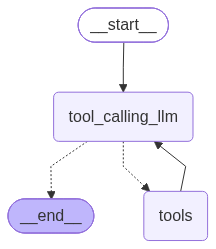

In [19]:
## StateGraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node Defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

## Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edge
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message(Result) from assistant is a tool call -> tools_condition route to the tools
    #If the latest message(Result) from assistant is not a tool call -> tools_condition route to the END
    tools_condition
    )
builder.add_edge("tools","tool_calling_llm")

## comnpile the graph
graph = builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [75]:
config={"configurable":{"thread_id":"1"}}
response = graph.invoke({"messages":"Hii, I am Alok"},config=config)

response

{'messages': [HumanMessage(content='Hii, I am Alok', additional_kwargs={}, response_metadata={}, id='51ac09bf-e53b-4dd4-bdf8-70e10bdac181'),
  AIMessage(content='Hi Alok! How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 12, 'prompt_tokens': 1923, 'total_tokens': 1935, 'completion_time': 0.026380967, 'completion_tokens_details': None, 'prompt_time': 0.132001087, 'prompt_tokens_details': None, 'queue_time': 0.04644678, 'total_time': 0.158382054}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1301a-3552-7522-882b-6425f991b4ca-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1923, 'output_tokens': 12, 'total_tokens': 1935})]}

In [78]:
response = graph.invoke({"messages":"What is my name ?"},config=config)
# for m in response["messages"]:
#     m.pretty_print()
print(response["messages"][-1].content)

Your name is Alok.


## Streaming

In [20]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [28]:
def superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

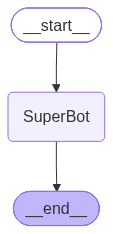

In [30]:
graph_builder = StateGraph(State)
graph_builder.add_node("SuperBot",superbot)

graph_builder.add_edge(START,"SuperBot")
graph_builder.add_edge("SuperBot",END)


graph = graph_builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [31]:
config={"configurable":{"thread_id":"1"}}
response = graph.invoke({"messages":"Hii, I am Alok , I am a software developer"},config=config)

response

{'messages': [HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='a65429b2-45aa-4c1e-bd69-2907be6612d4'),
  HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='c518ebfb-9b79-41b0-b308-9b1d58095ede'),
  AIMessage(content='Hi Alok! Nice to meet you. 👋\n\nIt’s great to connect with a fellow software developer. How can I assist you today?\n\nWhether you’re:\n*   Debugging a tricky piece of code\n*   Looking for architectural advice\n*   Exploring a new tech stack or language\n*   Preparing for technical interviews\n*   Or just want to chat about industry trends\n\nI’m here to help. What are you working on right now?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 98, 'prompt_tokens': 52, 'total_tokens': 150, 'completion_time': 0.186381338, 'completion_tokens_details': None, 'prompt_time': 0.003779689, 'prompt_tokens_details': None, 'q

### Streaming
Methods: .stream() and astream()
 - These methods are sync and async methods for streaming back results.


Additional parameters in streaming modes for graph state
- **values**: This streams the full state of the graph after each node is called.
- **updates**: This streams updates to the state of the graph after each node is called.



In [32]:
# Create a thread
config = {"configurable": {"thread_id": "2"}}

for chunk in graph.stream({"messages": "Hii, I am Alok , I am a software developer"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hi Alok! It's great to meet you.\n\nAs a fellow tech enthusiast, I'm ready to help you with whatever you're working on. Whether you need help debugging code, designing system architectures, exploring new technologies, or just discussing best practices, I'm here for it.\n\nWhat are you working on today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 79, 'total_tokens': 146, 'completion_time': 0.127369858, 'completion_tokens_details': None, 'prompt_time': 0.005383689, 'prompt_tokens_details': None, 'queue_time': 0.0448442, 'total_time': 0.132753547}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13478-eede-7ed3-b661-b4a1a8f0d477-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 67, 'total_tokens': 146})]}}


In [33]:
for chunk in graph.stream({"messages": "Hii, I am Alok , I am a software developer"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='0f448da5-cee1-4d3a-bec0-506355f350a2'), HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='1630f9cc-593a-4a0f-942e-abefe7247478'), HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='eb712b91-0cd3-4363-a496-90d54996f3e7'), AIMessage(content="Hi Alok! It's great to meet you.\n\nAs a fellow tech enthusiast, I'm ready to help you with whatever you're working on. Whether you need help debugging code, designing system architectures, exploring new technologies, or just discussing best practices, I'm here for it.\n\nWhat are you working on today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 79, 'total_tokens': 146, 'completion_time': 0.127369858, 'completion_tokens_details': None, 'prom

In [35]:
config = {"configurable": {"thread_id": "3"}}

for chunk in graph.stream({"messages": "Hii, I am Alok , I am a software developer"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Alok! Nice to meet you. 👋\n\nIt’s great to connect with a fellow software developer. How can I help you today? Whether you’re debugging a tricky issue, looking for code reviews, brainstorming architecture, or just want to chat about tech trends, I’m here to assist.\n\nWhat are you working on right now?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 72, 'prompt_tokens': 25, 'total_tokens': 97, 'completion_time': 0.216317648, 'completion_tokens_details': None, 'prompt_time': 0.001646638, 'prompt_tokens_details': None, 'queue_time': 1.268256853, 'total_time': 0.217964286}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1347a-1f89-7522-8b85-bcc83342c8df-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 25, 'output_tokens': 72, 'total_tokens': 97})]

In [36]:
for chunk in graph.stream({"messages": "I also do trading"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hii, I am Alok , I am a software developer', additional_kwargs={}, response_metadata={}, id='a388424b-e94b-43a4-8dcd-636898068e75'), AIMessage(content='Hi Alok! Nice to meet you. 👋\n\nIt’s great to connect with a fellow software developer. How can I help you today? Whether you’re debugging a tricky issue, looking for code reviews, brainstorming architecture, or just want to chat about tech trends, I’m here to assist.\n\nWhat are you working on right now?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 72, 'prompt_tokens': 25, 'total_tokens': 97, 'completion_time': 0.216317648, 'completion_tokens_details': None, 'prompt_time': 0.001646638, 'prompt_tokens_details': None, 'queue_time': 1.268256853, 'total_time': 0.217964286}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1347a-1f89-7